In [8]:
import time
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

In [9]:
display(df)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [10]:
df = pd.read_csv("insurance.csv")

df = pd.get_dummies(df, drop_first=True)
X = df.drop("charges", axis=1)
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

display(X_train)

array([[ 0.47222651, -1.75652513,  0.73433626, ...,  1.78316783,
        -0.59966106, -0.5723141 ],
       [ 0.54331294, -1.03308239, -0.91119211, ..., -0.56079971,
        -0.59966106, -0.5723141 ],
       [ 0.8987451 , -0.94368672, -0.91119211, ..., -0.56079971,
         1.66760869, -0.5723141 ],
       ...,
       [ 1.3252637 , -0.89153925, -0.91119211, ..., -0.56079971,
        -0.59966106, -0.5723141 ],
       [-0.16755139,  2.82086429,  0.73433626, ..., -0.56079971,
        -0.59966106,  1.74729228],
       [ 1.1120044 , -0.10932713, -0.91119211, ..., -0.56079971,
        -0.59966106,  1.74729228]], shape=(1070, 8))

Обучающая выборка имеет 1070 строк и 8 аттрибутов.

In [11]:
median_class = y_train.median()
y_train_class = (y_train>median_class).astype(int)
y_test_class = (y_test>median_class).astype(int)
clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train, y_train_class)
sample_probs = clf.predict_proba(X_test[:5])[:, 1]
sample_preds = clf.predict(X_test[:5])

results_class = pd.DataFrame(
    {
        "Вероятность (Сигмоида)":sample_probs,
        "Класс (Порог 0.5)":sample_preds,
        "Факт (Реальность)":y_test_class.iloc[:5].values
    }
)
display(results_class.round(3))
print(f"Accuracy: {accuracy_score(y_test_class, clf.predict(X_test)):.4f}")

,Вероятность (Сигмоида),Класс (Порог 0.5),Факт (Реальность)
0,0.558,1,0
1,0.190,0,0
2,1.000,1,1
3,0.485,0,0
4,0.978,1,1


Accuracy: 0.9104


Выборка выборка делит метрику на 2 класса, где идёт сравнения, является ли страховка выше среднего значения.

In [12]:
start_ols = time.time()
ols = LinearRegression()
ols.fit(X_train, y_train)
time_ols = time.time() - start_ols
pred_ols = ols.predict(X_test)

start_sgd = time.time()
sgd = SGDRegressor(
    max_iter=1000,
    tol=1e-3,
    eta0=0.01,
    learning_rate="adaptive",
    random_state=42
)
sgd.fit(X_train, y_train)
time_sgd = time.time() - start_sgd
pred_sgd = sgd.predict(X_test)

rmse_ols = np.sqrt(mean_squared_error(y_test, pred_ols))
r2_ols = r2_score(y_test, pred_ols)

rmse_sgd = np.sqrt(mean_squared_error(y_test, pred_sgd))
r2_sgd = r2_score(y_test, pred_sgd)

print(f"МНК (Аналитический) : RMSE = ${rmse_ols:,.2f} | R2 = {r2_ols:.4f} | Время = {time_ols:.5f} сек")
print(f"SGD (Итеративный)   : RMSE = ${rmse_sgd:,.2f} | R2 = {r2_sgd:.4f} | Время = {time_sgd:.5f} сек")

МНК (Аналитический) : RMSE = $5,796.28 | R2 = 0.7836 | Время = 0.00199 сек
SGD (Итеративный)   : RMSE = $5,796.14 | R2 = 0.7836 | Время = 0.07044 сек


Я пришёл к выводу, что метрики одинаковые.

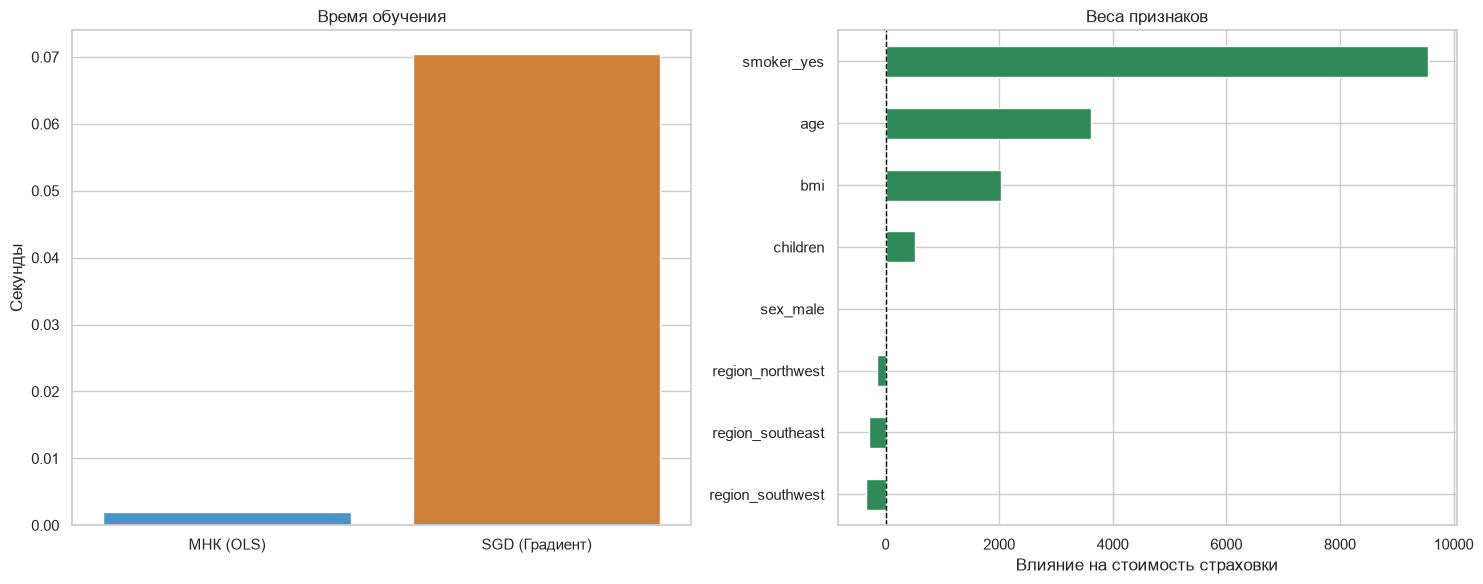

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    x=["МНК (OLS)", "SGD (Градиент)"],
    y=[time_ols, time_sgd],
    ax=axes[0],
    palette=["#3498db", "#e67e22"],
    hue=["МНК (OLS)", "SGD (Градиент)"],
)
axes[0].set_title("Время обучения")
axes[0].set_ylabel("Секунды")

weights = pd.Series(ols.coef_, index=X.columns).sort_values()
weights.plot(kind="barh", ax=axes[1], color="seagreen")
axes[1].axvline(0, color="black", linestyle="--", lw=1)
axes[1].set_title("Веса признаков")
axes[1].set_xlabel("Влияние на стоимость страховки")

plt.tight_layout()
plt.show()

Смотря на диаграмму, мы пришли к выводу, что на стоимсоть страховки влияет такие параметры как: курящий человек, индекс массы тела и наличие детей. На диаграмму совершенно не влияет такие параметры как: регион.